# Descarga de D-Fire y verificación de splits

Este notebook:

1. Descarga el dataset `sayedgamal99/smoke-fire-detection-yolo` (D-Fire en formato YOLO) desde Kaggle y lo deja en `data/`.
2. Explora la estructura de carpetas descargada.
3. Cuenta imágenes y labels por split (train/val/test) y los compara contra el split oficial (14.122 / 3.099 / 4.306).
4. Verifica que cada imagen tenga su `.txt` de labels correspondiente (y viceversa).
5. Confirma el orden de los índices de clase contra los totales oficiales de cajas y con una inspección visual.
6. Revisa la integridad de los labels (cajas degeneradas o fuera de rango).
7. Genera `configs/data.yaml` y `configs/data_noneg.yaml` (train sin imágenes "none", para R5).

## 1. Descarga

Usamos `kagglehub`, que maneja la autenticación con Kaggle (pide usuario y API key la primera vez: Kaggle > Settings > Create New Token, descarga `kaggle.json`). `kagglehub` baja el dataset a una cache temporal dentro de `data/`; después movemos su contenido a `data/` y borramos la cache, de modo que el layout final es siempre `data/data/{train,val,test}/{images,labels}` + `data/data.yaml`, que es donde el resto del repo espera encontrarlo.

Si el dataset ya está en `data/`, la descarga se saltea.

In [1]:
import os
import random
import shutil
from collections import Counter
from pathlib import Path

import kagglehub
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

DATASET_SLUG = "sayedgamal99/smoke-fire-detection-yolo"
SEED = 42

REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"
CONFIG_DIR = REPO_ROOT / "configs"
FIG_DIR = REPO_ROOT / "figures"
for d in (DATA_DIR, CONFIG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

DATASET_ROOT = DATA_DIR
if (DATASET_ROOT / "data" / "train" / "images").is_dir():
    print("Dataset ya presente en:", DATASET_ROOT)
else:
    cache_dir = DATA_DIR / ".kagglehub_cache"
    os.environ["KAGGLEHUB_CACHE"] = str(cache_dir)
    downloaded = Path(kagglehub.dataset_download(DATASET_SLUG))
    for entry in downloaded.iterdir():
        shutil.move(str(entry), str(DATASET_ROOT / entry.name))
    shutil.rmtree(cache_dir)
    print("Dataset descargado y movido a:", DATASET_ROOT)

Dataset ya presente en: C:\Proyectos\CV2\detección_incendios\data


## 2. Estructura de carpetas

Antes de asumir nada sobre `train/val/test` o `images/labels`, listamos el árbol real tal como quedó en `data/`.

In [2]:
def print_tree(path: Path, prefix: str = "", max_depth: int = 4, depth: int = 0, max_entries: int = 15):
    if depth >= max_depth:
        return
    entries = sorted(path.iterdir(), key=lambda p: (p.is_file(), p.name.lower()))
    for i, entry in enumerate(entries[:max_entries]):
        connector = "└── " if i == len(entries) - 1 else "├── "
        suffix = ""
        if entry.is_dir():
            n_items = sum(1 for _ in entry.iterdir())
            suffix = f"  ({n_items} items)"
        print(prefix + connector + entry.name + suffix)
        if entry.is_dir():
            extension = "    " if i == len(entries) - 1 else "│   "
            print_tree(entry, prefix + extension, max_depth, depth + 1, max_entries)
    if len(entries) > max_entries:
        print(prefix + f"... (+{len(entries) - max_entries} más)")

print_tree(DATASET_ROOT, max_entries=5)

├── data  (3 items)
│   ├── test  (2 items)
│   │   ├── images  (4306 items)
│   │   │   ├── AoF06723.jpg
│   │   │   ├── AoF06724.jpg
│   │   │   ├── AoF06725.jpg
│   │   │   ├── AoF06726.jpg
│   │   │   ├── AoF06727.jpg
│   │   │   ... (+4301 más)
│   │   └── labels  (4306 items)


│   │       ├── AoF06723.txt
│   │       ├── AoF06724.txt
│   │       ├── AoF06725.txt
│   │       ├── AoF06726.txt
│   │       ├── AoF06727.txt
│   │       ... (+4301 más)
│   ├── train  (2 items)
│   │   ├── images  (14122 items)


│   │   │   ├── AoF00000.jpg
│   │   │   ├── AoF00001.jpg
│   │   │   ├── AoF00002.jpg
│   │   │   ├── AoF00003.jpg
│   │   │   ├── AoF00004.jpg
│   │   │   ... (+14117 más)
│   │   └── labels  (14122 items)


│   │       ├── AoF00000.txt
│   │       ├── AoF00001.txt
│   │       ├── AoF00002.txt
│   │       ├── AoF00003.txt
│   │       ├── AoF00004.txt
│   │       ... (+14117 más)
│   └── val  (2 items)
│       ├── images  (3099 items)
│       │   ├── AoF00008.jpg
│       │   ├── AoF00009.jpg
│       │   ├── AoF00011.jpg
│       │   ├── AoF00014.jpg
│       │   ├── AoF00018.jpg
│       │   ... (+3094 más)
│       └── labels  (3099 items)


│           ├── AoF00008.txt
│           ├── AoF00009.txt
│           ├── AoF00011.txt
│           ├── AoF00014.txt
│           ├── AoF00018.txt
│           ... (+3094 más)
└── data.yaml


## 3. Ubicar splits e imágenes/labels

A partir del árbol impreso arriba, ajustar `SPLIT_DIRS` si los nombres de carpeta no coinciden con lo esperado (`train`, `val`, `test`) o si `images`/`labels` están anidados distinto.

In [3]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

def find_split_dirs(root: Path):
    """Busca subcarpetas cuyo nombre matchee train/val/test en todo el árbol."""
    candidates = {"train": [], "val": [], "valid": [], "test": []}
    for p in root.rglob("*"):
        if p.is_dir() and p.name.lower() in candidates:
            candidates[p.name.lower()].append(p)
    return candidates

split_candidates = find_split_dirs(DATASET_ROOT)
for name, dirs in split_candidates.items():
    for d in dirs:
        print(f"{name}: {d.relative_to(DATASET_ROOT)}")

train: data\train
val: data\val
test: data\test


In [4]:
SPLIT_DIRS = {
    "train": split_candidates["train"][0] if split_candidates["train"] else None,
    "val": (split_candidates["val"] or split_candidates["valid"] or [None])[0],
    "test": split_candidates["test"][0] if split_candidates["test"] else None,
}
SPLIT_DIRS

{'train': WindowsPath('C:/Proyectos/CV2/detección_incendios/data/data/train'),
 'val': WindowsPath('C:/Proyectos/CV2/detección_incendios/data/data/val'),
 'test': WindowsPath('C:/Proyectos/CV2/detección_incendios/data/data/test')}

## 4. Conteo de imágenes y labels por split

Referencia: split oficial de D-Fire, **14.122 train / 3.099 val / 4.306 test**, total 21.527 imágenes (coincide con el `data.yaml` que trae el paquete). Si no cierra exacto, el `assert` corta acá: hay que revisar `SPLIT_DIRS` antes de seguir.

In [5]:
OFFICIAL_SPLIT = {"train": 14122, "val": 3099, "test": 4306}

def images_and_labels(split_dir: Path):
    images = sorted([p for p in split_dir.rglob("*") if p.suffix.lower() in IMAGE_EXTS])
    labels = sorted([p for p in split_dir.rglob("*.txt")])
    return images, labels

rows = []
split_files = {}
for split, d in SPLIT_DIRS.items():
    if d is None:
        print(f"[!] No se encontró carpeta para split '{split}'")
        continue
    images, labels = images_and_labels(d)
    split_files[split] = {"images": images, "labels": labels}
    rows.append({"split": split, "n_imagenes": len(images), "n_labels": len(labels), "oficial": OFFICIAL_SPLIT[split]})

df_counts = pd.DataFrame(rows)
for _, r in df_counts.iterrows():
    assert r["n_imagenes"] == r["oficial"], f"{r['split']}: {r['n_imagenes']} imágenes, se esperaban {r['oficial']}"
df_counts.loc["total"] = ["total", *df_counts[["n_imagenes", "n_labels", "oficial"]].sum()]
df_counts

,split,n_imagenes,n_labels,oficial
0,train,14122,14122,14122
1,val,3099,3099,3099
2,test,4306,4306,4306
total,total,21527,21527,21527


## 5. Chequeo de correspondencia imagen ↔ label

Cada imagen debe tener un `.txt` con el mismo stem (aunque esté vacío, para las imágenes "none"). Si el `.txt` no existe, D-Fire lo trata como imagen sin objetos igual — pero conviene saber cuántas caen en cada caso antes del EDA.

In [6]:
def has_boxes(lbl_path: Path) -> bool:
    return bool(lbl_path.read_text().strip())

match_rows = []
for split, files in split_files.items():
    img_stems = {p.stem for p in files["images"]}
    lbl_stems = {p.stem for p in files["labels"]}
    match_rows.append({
        "split": split,
        "imagenes_sin_label": len(img_stems - lbl_stems),
        "labels_sin_imagen": len(lbl_stems - img_stems),
        "labels_vacios_none": sum(1 for p in files["labels"] if not has_boxes(p)),
    })

df_match = pd.DataFrame(match_rows)
assert df_match["labels_vacios_none"].sum() == 9838, "D-Fire tiene 9.838 imágenes sin fuego ni humo"
df_match

,split,imagenes_sin_label,labels_sin_imagen,labels_vacios_none
0,train,0,0,6458
1,val,0,0,1375
2,test,0,0,2005


## 6. Orden real de índices de clase

**Regla dura del plan:** no asumir `names: [smoke, fire]`. El `data.yaml` del paquete lo dice, pero tiene el comentario `# Replace with your actual class names`, así que no alcanza. Lo verificamos de dos formas independientes:

1. **Totales de cajas.** El paper de D-Fire reporta 11.865 cajas de humo y 14.692 de fuego. Contamos las cajas por índice en los tres splits y asignamos cada índice al nombre cuyo total coincide.
2. **Inspección visual** de imágenes que contienen ambas clases.

In [7]:
# Buscar cualquier archivo de metadata de clases que traiga el dataset
for pattern in ("*.yaml", "*.yml", "classes.txt", "*.names"):
    for p in DATASET_ROOT.rglob(pattern):
        print("---", p.relative_to(DATASET_ROOT), "---")
        print(p.read_text(encoding="utf-8", errors="replace"))
        print()

--- data.yaml ---
path: /kaggle/working/D Fire Dataset  # dataset root dir
train: data/train/images  # train images (relative to 'path')
val: data/val/images  # val images (relative to 'path')
test: data/test/images  # test images (relative to 'path')

# Classes
names: ['smoke', 'fire']  # Replace with your actual class names

# Counts
nc: 2  # number of classes
train_count: 14122
val_count: 3099
test_count: 4306




In [8]:
OFFICIAL_BOXES = {"smoke": 11865, "fire": 14692}  # paper D-Fire

class_counter = Counter()
for split, files in split_files.items():
    for lbl_path in files["labels"]:
        for line in lbl_path.read_text().splitlines():
            if line.strip():
                class_counter[(split, int(line.split()[0]))] += 1

box_counts = (
    pd.Series(class_counter).rename_axis(["split", "indice"]).unstack(fill_value=0)
    .reindex(["train", "val", "test"])
)
box_counts.loc["total"] = box_counts.sum()
display(box_counts)

totals = box_counts.loc["total"].to_dict()
CLASS_NAMES = {
    idx: name
    for idx, n in totals.items()
    for name, n_official in OFFICIAL_BOXES.items()
    if n == n_official
}
assert CLASS_NAMES == {0: "smoke", 1: "fire"}, f"Orden de clases inesperado: {CLASS_NAMES} (totales {totals})"
print("Orden confirmado por totales oficiales:", CLASS_NAMES)

indice,0,1
split,,
train,7794,9638
val,1756,2176
test,2315,2878
total,11865,14692


Orden confirmado por totales oficiales: {0: 'smoke', 1: 'fire'}


### Verificación visual

Imágenes de train con ambas clases: en una misma foto se ve qué índice marca el fuego y cuál el humo. La figura queda en `figures/verificacion_clases.png`.

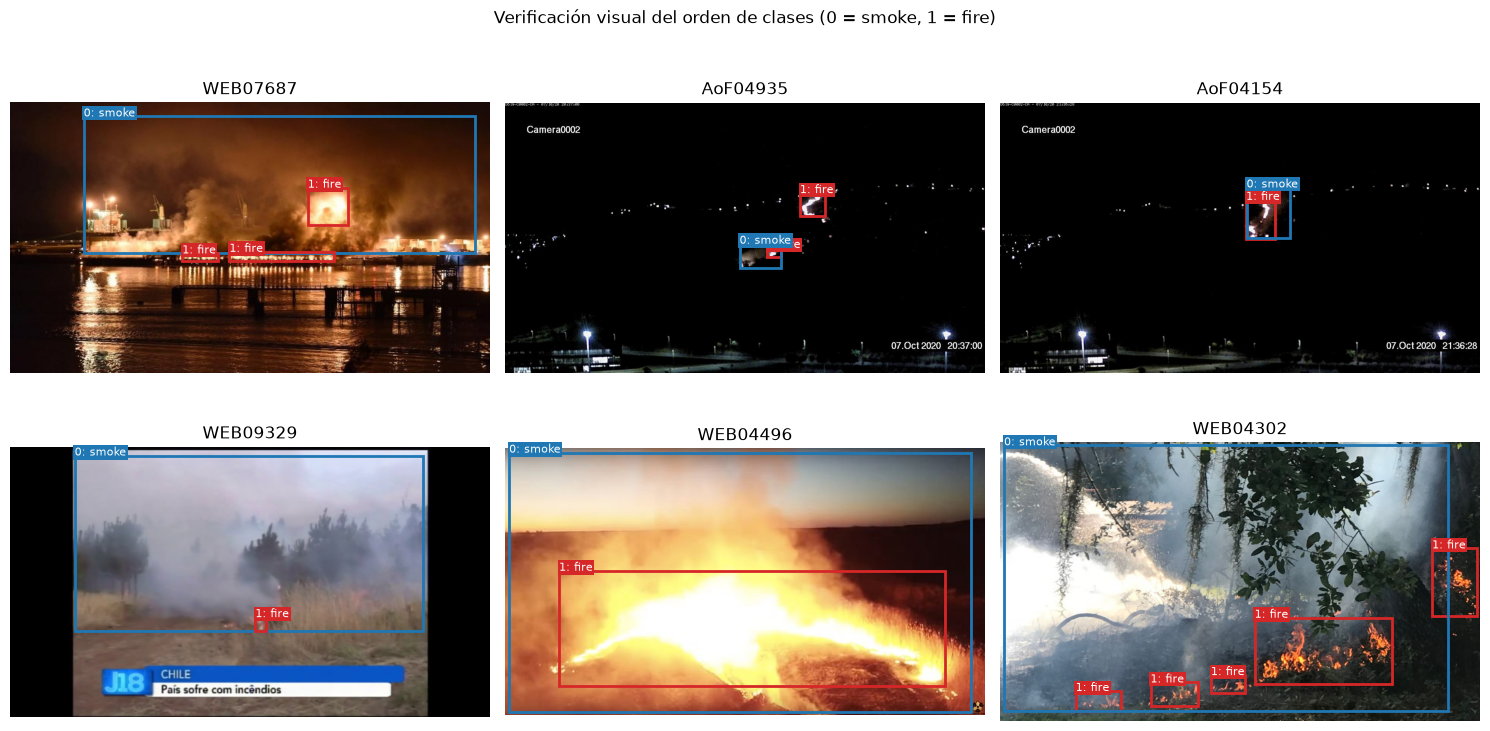

In [9]:
CLASS_COLORS = {"smoke": "tab:blue", "fire": "tab:red"}

def read_boxes(lbl_path: Path):
    boxes = []
    for line in lbl_path.read_text().splitlines():
        if line.strip():
            c, x, y, w, h = line.split()[:5]
            boxes.append((int(c), float(x), float(y), float(w), float(h)))
    return boxes

train_images = {p.stem: p for p in split_files["train"]["images"]}
both_classes = [p for p in split_files["train"]["labels"] if {b[0] for b in read_boxes(p)} == {0, 1}]
random.seed(SEED)
sample = random.sample(both_classes, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, lbl_path in zip(axes.flat, sample):
    img = Image.open(train_images[lbl_path.stem]).convert("RGB")
    W, H = img.size
    ax.imshow(img)
    for c, x, y, w, h in read_boxes(lbl_path):
        name = CLASS_NAMES[c]
        x0, y0 = (x - w / 2) * W, (y - h / 2) * H
        ax.add_patch(patches.Rectangle((x0, y0), w * W, h * H, fill=False, lw=2, color=CLASS_COLORS[name]))
        ax.text(x0, y0, f"{c}: {name}", color="white", fontsize=8,
                bbox=dict(facecolor=CLASS_COLORS[name], pad=1, lw=0))
    ax.set_title(lbl_path.stem)
    ax.axis("off")
fig.suptitle("Verificación visual del orden de clases (0 = smoke, 1 = fire)")
fig.tight_layout()
fig.savefig(FIG_DIR / "verificacion_clases.png", dpi=150, bbox_inches="tight")

## 7. Integridad de labels

Buscamos líneas mal formadas, cajas degeneradas (`w` o `h` = 0) y coordenadas fuera de `[0, 1]`.

Ultralytics (`verify_image_label`) **descarta la imagen entera** si alguna coordenada supera 1,01, así que esas imágenes desaparecen de train/val/test sin aviso más allá de un warning. Las cajas degeneradas no descartan la imagen, pero en test cuentan como ground truth imposible de matchear (falso negativo).

**Decisión:** no modificamos los labels originales, para que los resultados sigan siendo comparables con otros trabajos sobre D-Fire. Lo reportamos como limitación del dataset en el paper.

In [10]:
ULTRALYTICS_TOL = 1.01  # umbral de verify_image_label

issues = []
for split, files in split_files.items():
    for lbl_path in files["labels"]:
        for n_line, line in enumerate(lbl_path.read_text().splitlines(), start=1):
            if not line.strip():
                continue
            vals = line.split()
            if len(vals) != 5:
                issues.append({"split": split, "label": lbl_path.name, "linea": n_line, "problema": "formato"})
                continue
            c, (x, y, w, h) = int(vals[0]), map(float, vals[1:])
            coords = (x, y, w, h)
            if w <= 0 or h <= 0:
                problema = "caja_degenerada"
            elif min(coords) < 0 or max(coords) > 1:
                problema = "fuera_de_rango"
            else:
                continue
            issues.append({
                "split": split, "label": lbl_path.name, "linea": n_line,
                "clase": CLASS_NAMES.get(c, c), "x": x, "y": y, "w": w, "h": h,
                "problema": problema,
                "ultralytics_descarta_imagen": max(coords) > ULTRALYTICS_TOL,
            })

df_issues = pd.DataFrame(issues)
display(df_issues.groupby(["split", "problema"]).size().unstack(fill_value=0))
print("Imágenes que Ultralytics va a descartar:",
      df_issues.loc[df_issues["ultralytics_descarta_imagen"], ["split", "label"]].values.tolist())
df_issues

problema,caja_degenerada,fuera_de_rango
split,,
test,4,8
train,13,0
val,1,0


Imágenes que Ultralytics va a descartar: [['test', 'WEB10769.txt'], ['test', 'WEB10775.txt'], ['test', 'WEB11598.txt'], ['test', 'WEB11600.txt']]


,split,label,linea,clase,x,y,w,h,problema,ultralytics_descarta_imagen
0,train,AoF05470.txt,2,smoke,0.558594,0.466667,0.000000,0.000000,caja_degenerada,False
1,train,AoF06155.txt,2,smoke,0.812500,0.337500,0.000000,0.000000,caja_degenerada,False
2,train,AoF06348.txt,2,smoke,0.753125,0.258333,0.000000,0.000000,caja_degenerada,False
3,train,AoF06439.txt,2,smoke,0.712500,0.275000,0.000000,0.000000,caja_degenerada,False
4,train,AoF06456.txt,2,smoke,0.147656,0.437500,0.000000,0.000000,caja_degenerada,False
5,train,PublicDataset00056.txt,5,fire,0.329688,0.815278,0.000000,0.002778,caja_degenerada,False
6,train,WEB04243.txt,5,fire,0.268555,0.416667,0.000000,0.000000,caja_degenerada,False
7,train,WEB04527.txt,2,fire,0.553000,0.733096,0.000000,0.000000,caja_degenerada,False
8,train,WEB04742.txt,5,fire,0.387500,0.491667,0.000000,0.000000,caja_degenerada,False
9,train,WEB04849.txt,5,fire,0.148438,0.422222,0.000000,0.000000,caja_degenerada,False


## 8. Configs de entrenamiento

El `data.yaml` del paquete apunta a `/kaggle/working/...`, así que no sirve. Generamos:

- `configs/data.yaml` — split oficial completo (runs `_neg`).
- `configs/data_noneg.yaml` — **train** sin las imágenes "none" (run R5, **H2**); val y test quedan intactos para que la comparación valga.

Sin clave `path`: Ultralytics resuelve las rutas relativas a la carpeta del yaml, así que los configs funcionan en cualquier máquina sin editarlos. La lista de imágenes de R5 va en `data/data/train_noneg.txt`, con rutas relativas a ese archivo (`./train/images/...`), que es como Ultralytics las interpreta.

In [11]:
def rel_to_configs(p: Path) -> str:
    return Path(os.path.relpath(p, CONFIG_DIR)).as_posix()

names_block = "\n".join(f"  {i}: {n}" for i, n in sorted(CLASS_NAMES.items()))
header = "# Generado por descarga.ipynb, no editar a mano.\n# Sin `path`: Ultralytics resuelve las rutas relativas a esta carpeta.\n"
val_test = (
    f"val: {rel_to_configs(SPLIT_DIRS['val'] / 'images')}\n"
    f"test: {rel_to_configs(SPLIT_DIRS['test'] / 'images')}\n"
    f"\nnames:\n{names_block}\n"
)

# Train sin negativos: lista de imágenes con al menos una caja
train_labels = {p.stem: p for p in split_files["train"]["labels"]}
train_pos = [img for img in split_files["train"]["images"] if has_boxes(train_labels[img.stem])]
noneg_list = SPLIT_DIRS["train"].parent / "train_noneg.txt"
noneg_list.write_text(
    "\n".join("./" + img.relative_to(noneg_list.parent).as_posix() for img in train_pos) + "\n",
    encoding="utf-8",
)

(CONFIG_DIR / "data.yaml").write_text(
    header + f"train: {rel_to_configs(SPLIT_DIRS['train'] / 'images')}\n" + val_test, encoding="utf-8"
)
(CONFIG_DIR / "data_noneg.yaml").write_text(
    header + "# Train sin imágenes 'none' (R5 / H2). Val y test idénticos a data.yaml.\n"
    + f"train: {rel_to_configs(noneg_list)}\n" + val_test, encoding="utf-8"
)

for name in ("data.yaml", "data_noneg.yaml"):
    print(f"--- configs/{name} ---")
    print((CONFIG_DIR / name).read_text(encoding="utf-8"))

--- configs/data.yaml ---
# Generado por descarga.ipynb, no editar a mano.
# Sin `path`: Ultralytics resuelve las rutas relativas a esta carpeta.
train: ../data/data/train/images
val: ../data/data/val/images
test: ../data/data/test/images

names:
  0: smoke
  1: fire

--- configs/data_noneg.yaml ---
# Generado por descarga.ipynb, no editar a mano.
# Sin `path`: Ultralytics resuelve las rutas relativas a esta carpeta.
# Train sin imágenes 'none' (R5 / H2). Val y test idénticos a data.yaml.
train: ../data/data/train_noneg.txt
val: ../data/data/val/images
test: ../data/data/test/images

names:
  0: smoke
  1: fire



In [12]:
import yaml

# Chequeo: todas las rutas resuelven desde configs/ y R5 tiene exactamente train - negativos
n_train_neg = df_match.set_index("split").loc["train", "labels_vacios_none"]
for name in ("data.yaml", "data_noneg.yaml"):
    cfg = yaml.safe_load((CONFIG_DIR / name).read_text(encoding="utf-8"))
    assert cfg["names"] == CLASS_NAMES
    for k in ("train", "val", "test"):
        assert (CONFIG_DIR / cfg[k]).resolve().exists(), f"{name}: no existe {cfg[k]}"

listed = [noneg_list.parent / l for l in noneg_list.read_text(encoding="utf-8").splitlines()]
assert all(p.exists() for p in listed)
assert len(listed) == OFFICIAL_SPLIT["train"] - n_train_neg
print(f"OK: data_noneg train = {len(listed)} imágenes ({OFFICIAL_SPLIT['train']} - {n_train_neg} negativos)")

OK: data_noneg train = 7664 imágenes (14122 - 6458 negativos)
